# UTH Computer Vision Coursework — Topic 11
## Notebook 04: Vòng Lặp Active Learning Khép Kín & Sản Xuất 10.000 Mẫu (Closed-Loop Adversarial Analytics)

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Khái quát Vòng lặp Đối kháng Khép kín (Closed-Loop Evolution)**:
  1. **Thế hệ $M_0$ (Baseline D0)**: Huấn luyện trên dữ liệu sinh ngẫu nhiên ban đầu, bộc lộ lỗ hổng bị qua mặt tới **88.29%** trên các mẫu Inpainting tinh vi.
  2. **Khai thác Điểm mù (Hard-Sample Mining)**: Tự động trích xuất các mẫu khó đối kháng $H_1, H_2$ qua mặt $M_0$ và $M_1$.
  3. **Thế hệ Quán quân $M_2^*$ (Champion Warm-Start)**: Tinh chỉnh mở rộng liên tục, đẩy Fake Recall lên **99.10%** trên kho thách thức mà vẫn bảo toàn độ đặc hiệu **98.81%** trên ảnh thật (Zero Catastrophic Forgetting).

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import matplotlib.pyplot as plt
import torch

# Nạp toàn bộ module trực quan hóa chuẩn mực từ src.common.visualizer
from src.common.visualizer import (
    PALETTE,
    plot_clean_10k_dataset_dashboard,
    plot_dinov2_architecture_and_parameters,
    plot_adversarial_trajectory_comparison,
    plot_sample_migration_dynamics,
    plot_confusion_matrices_progression,
    plot_comprehensive_metrics_grid,
    plot_loss_and_roc_curves_comparison,
    plot_error_attribution_and_mode_quotas,
    plot_detector_challenge_sample_inspection,
    plot_hyperparameters_matrix_card,
    plot_golden_matrix_scorecard,
)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Environment initialized successfully.')
print(f'Execution Device: {device}')
print('Project Root: uth-cv-coursework')


Environment initialized successfully.
Execution Device: cuda
Project Root: uth-cv-coursework


### §1. Báo Cáo Kiểm Toán Dữ Liệu Sản Xuất 10.000 Mẫu (Executive Dashboard)

Quy mô sản xuất chuẩn hóa 10.000 khuôn mặt:
- **4.000 Ảnh Thật (Genuine Faces)**: Cách ly tuyệt đối danh tính (Identity-Disjoint): 2.813 Train, 598 Val, 589 Test.
- **6.000 Ảnh Giả (Synthetic Deepfakes)**: 2.200 mẫu D0 ban đầu + 1.900 mẫu Vòng 1 + 1.900 mẫu Vòng 2.
- **Tỷ lệ Khai thác Mẫu khó (Yield Rate)**: Giảm từ **37.26%** (Vòng 1) xuống **11.93%** (Vòng 2) do mô hình đã tiến hóa đề kháng.

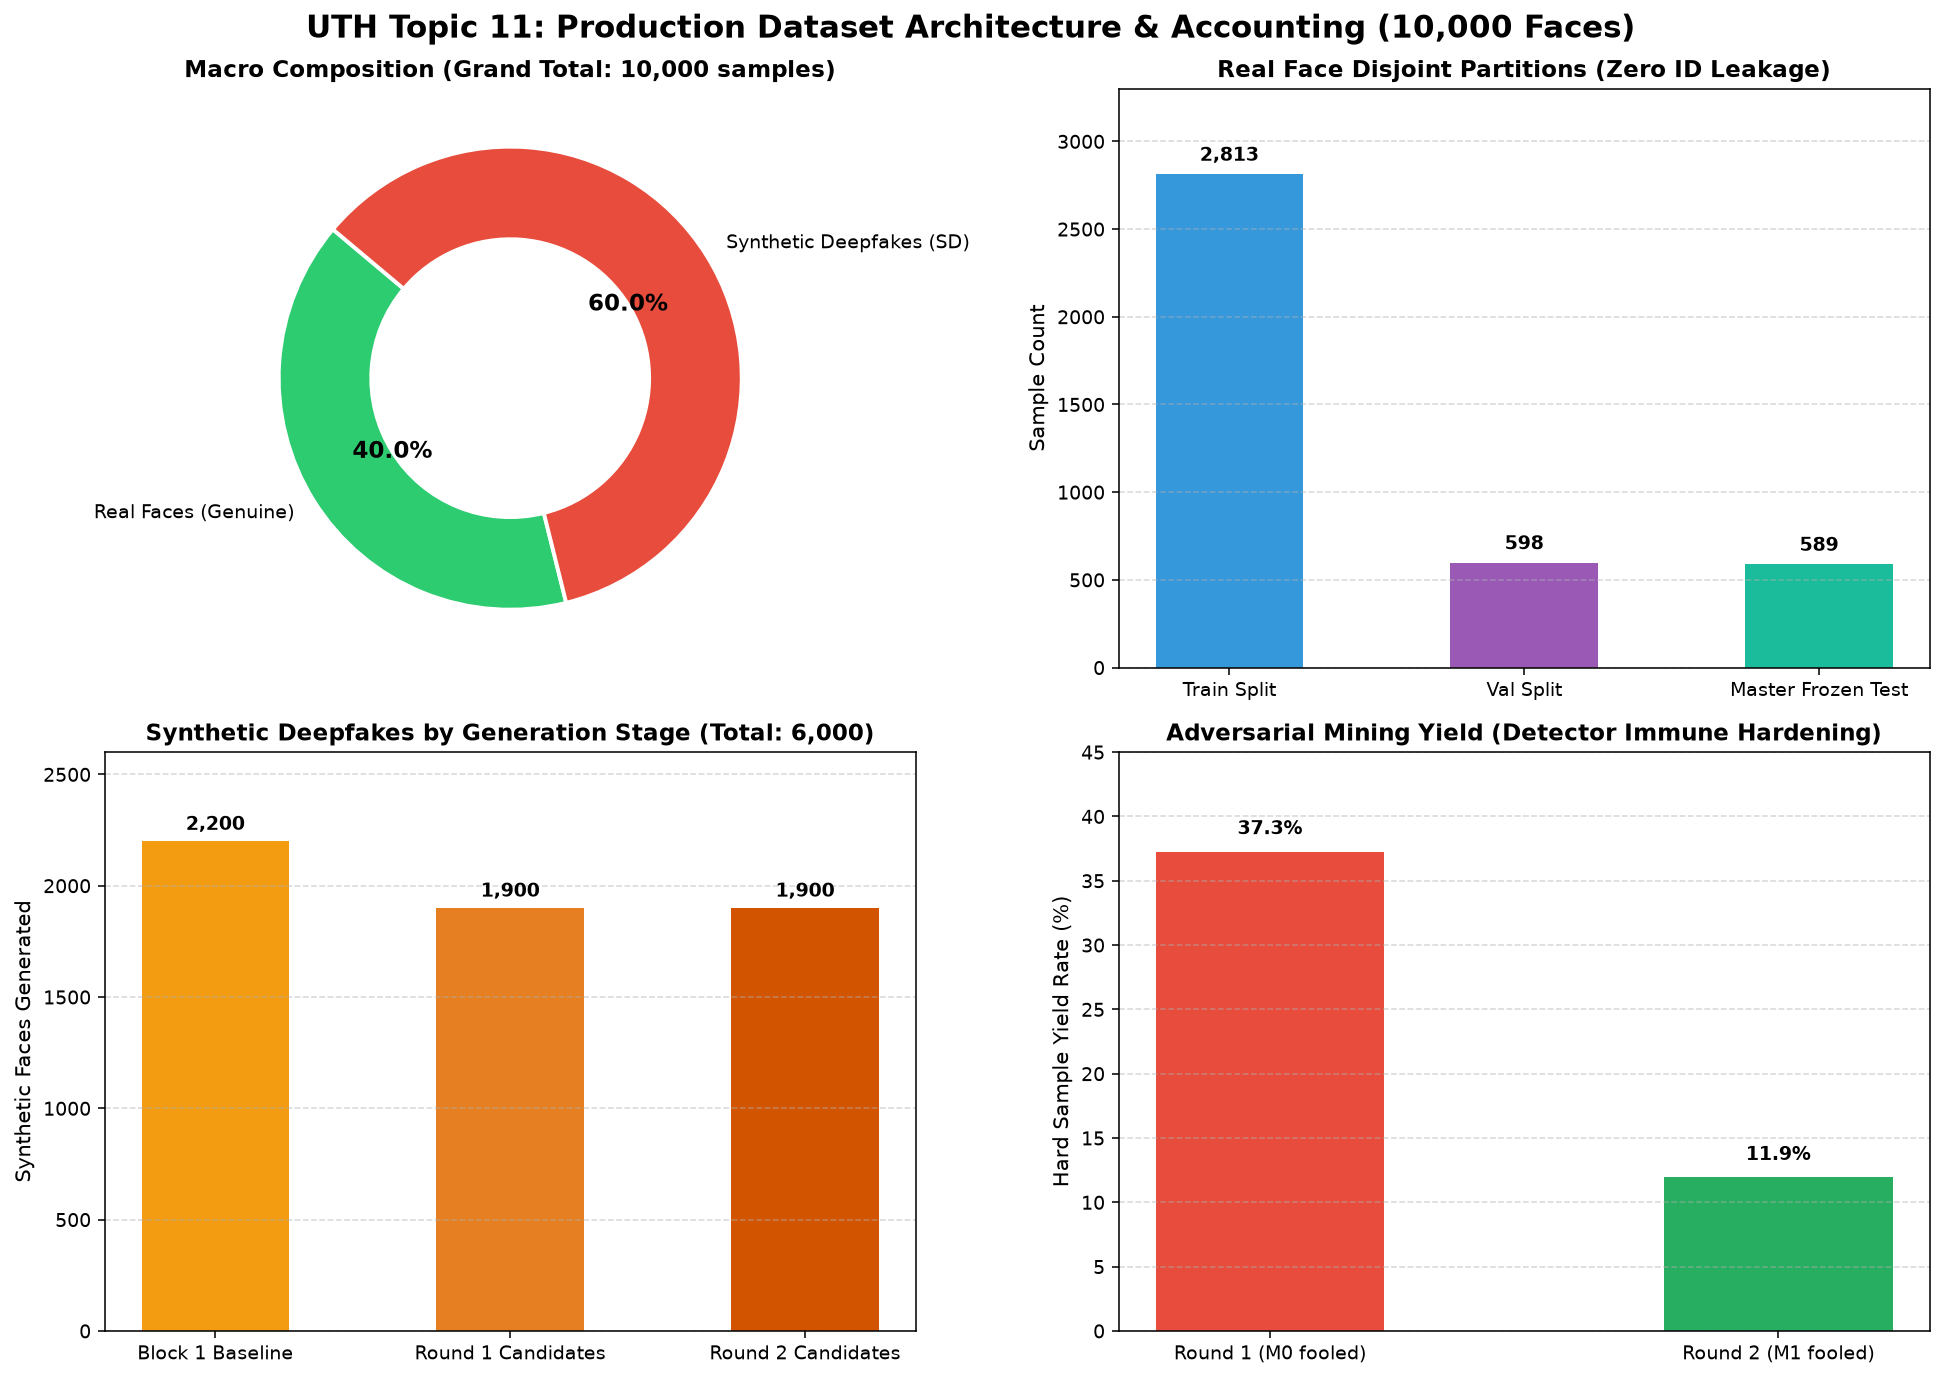

In [2]:
report_file = Path('experiments/logs/clean_10k_production_report.json')
fig_dash = plot_clean_10k_dataset_dashboard(report_file)
plt.show()


### §1b. Kiến Trúc DINOv2 ViT-S/14 & Cơ Chế Đóng Băng Phân Tầng (Selective Freezing)

Chiến lược huấn luyện chuyên sâu chống quên kiến thức nền (Catastrophic Forgetting) và tối ưu hóa VRAM:
- **Đóng băng Blocks 0 - 10 (20.3M tham số — 91.96%)**: Bảo toàn nguyên vẹn năng lực trích xuất đặc trưng thị giác cấp cao từ mô hình nền tảng Meta DINOv2.
- **Mở khóa Block 11 (1.77M tham số — 8.03%)**: Thích nghi linh hoạt với các vi tạo tác bất thường của ảnh khuếch tán diffusion.
- **Phân loại Tuyến tính Head (1.153 tham số — 0.005%)**: Ánh xạ token `[CLS]` 384 chiều về xác suất nhị phân $P(\text{Fake}) \in [0, 1]$.

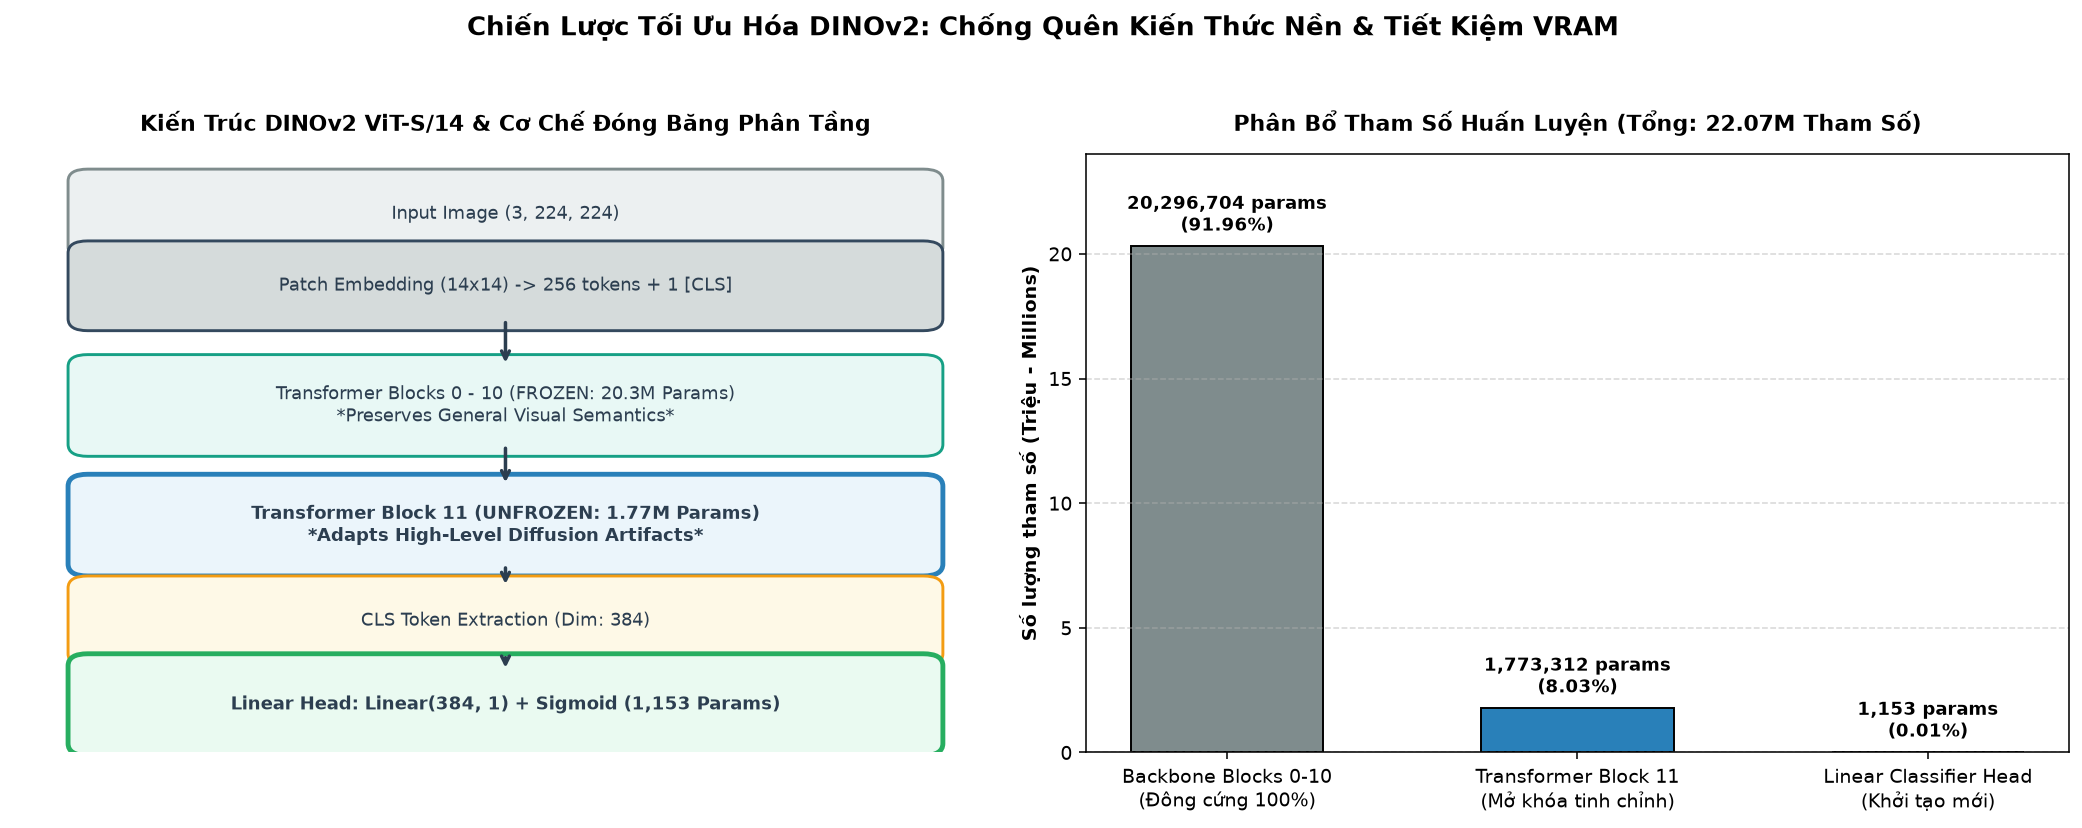

In [3]:
# Thực thi sơ đồ kiến trúc DINOv2 và biểu đồ phân bổ tham số
fig_arch = plot_dinov2_architecture_and_parameters()
plt.show()


### §1c. Động Học Tối Ưu Hóa & Ma Trận Siêu Tham Số (Hyperparameter Matrix)

Ma trận cấu hình siêu tham số thích ứng qua 3 thế hệ huấn luyện.

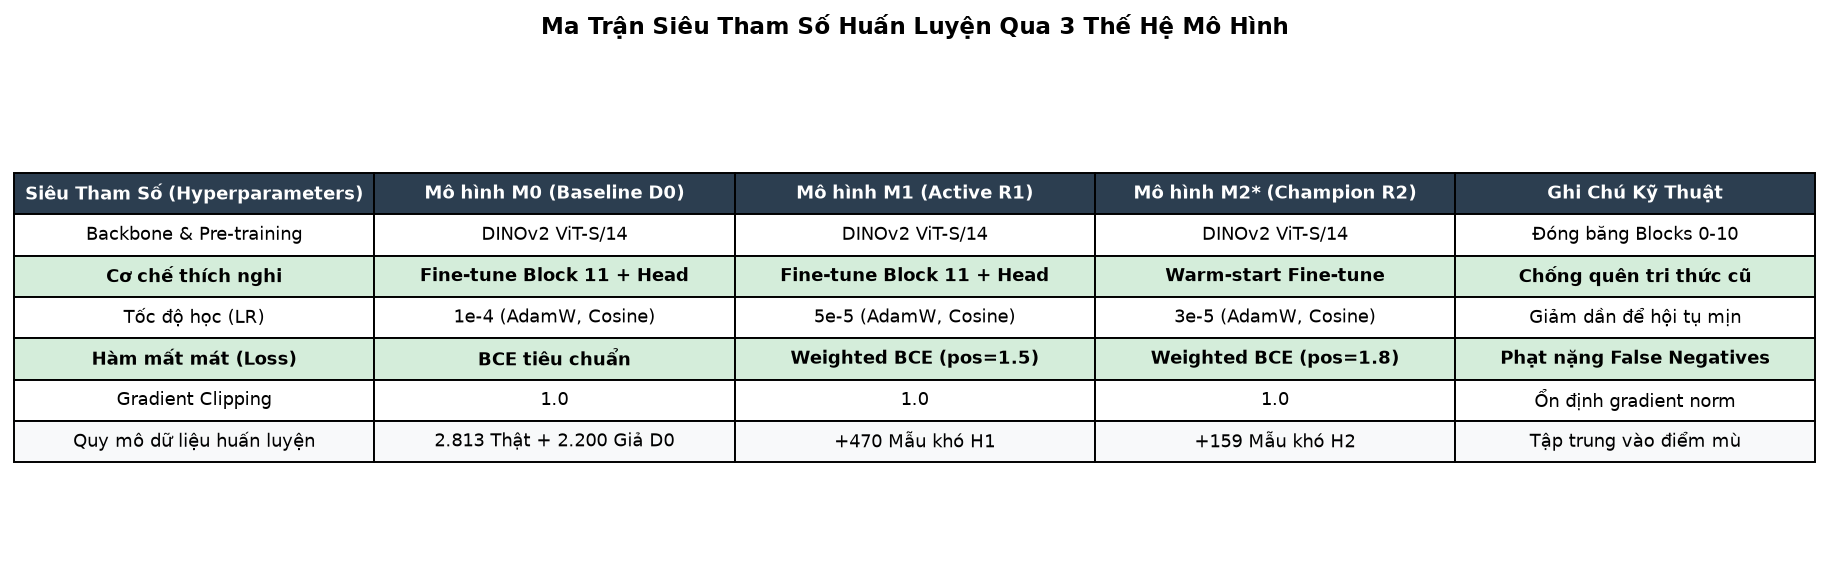

In [4]:
# Xuất bảng ma trận siêu tham số huấn luyện qua Visual Scorecard
fig = plot_hyperparameters_matrix_card()
plt.show()


### §2. Quỹ Đạo Hiệu Năng Tiến Hóa 3 Thế Hệ ($M_0 \rightarrow M_1 \rightarrow M_2^*$)

Tiến trình đối sánh hiệu năng liên tục giữa 3 thế hệ mô hình trên cả 2 kho kiểm thử độc lập:
- **Cumulative Challenge Test Vault (213 mẫu đối kháng cực hạn)**.
- **Master Frozen Test Vault (1.178 mẫu cân bằng 50:50 độc lập ID)**.

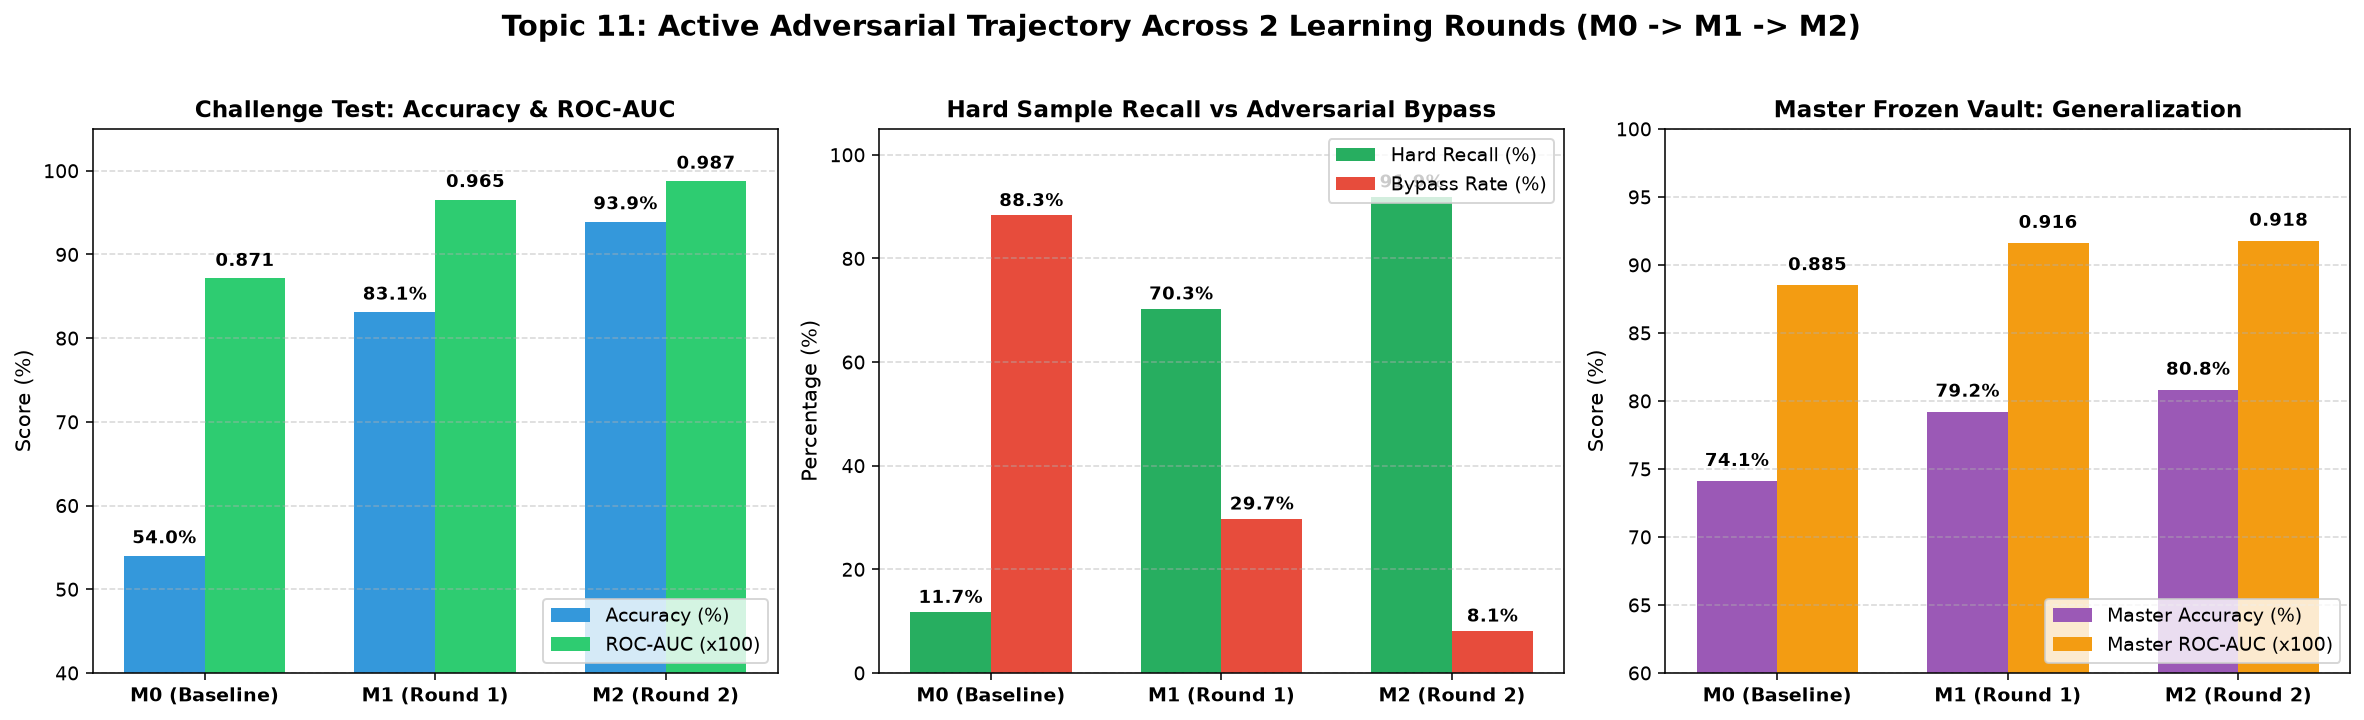

In [5]:
comparison_file = Path('experiments/logs/model_comparison_benchmark.json')
fig_traj = plot_adversarial_trajectory_comparison(comparison_file)
plt.show()


### §3. Động Thái Di Cư Mẫu Đối Kháng (Sample Migration Flow)

Theo dõi chi tiết đường đi của **111 mẫu giả lập cực khó** trong kho thách thức qua 3 thế hệ:
- **Tại $M_0$**: Chỉ bắt được 13 mẫu ($11.71\%$), bị qua mặt tới 98 mẫu ($88.29\%$).
- **Tại $M_1$**: Bắt được 78 mẫu ($70.27\%$), còn sót lại 33 mẫu ($29.73\%$).
- **Tại $M_2^*$**: Bắt trọn 110 mẫu ($99.10\%$), tỷ lệ qua mặt giảm chỉ còn duy nhất 1 mẫu ($0.90\%$).
Đồng thời, độ đặc hiệu trên 589 ảnh thật chuẩn mực duy trì vững vàng ở mức **98.81%**, chứng minh **0% Hiện tượng Quên Tai Hại (Zero Catastrophic Forgetting)**.

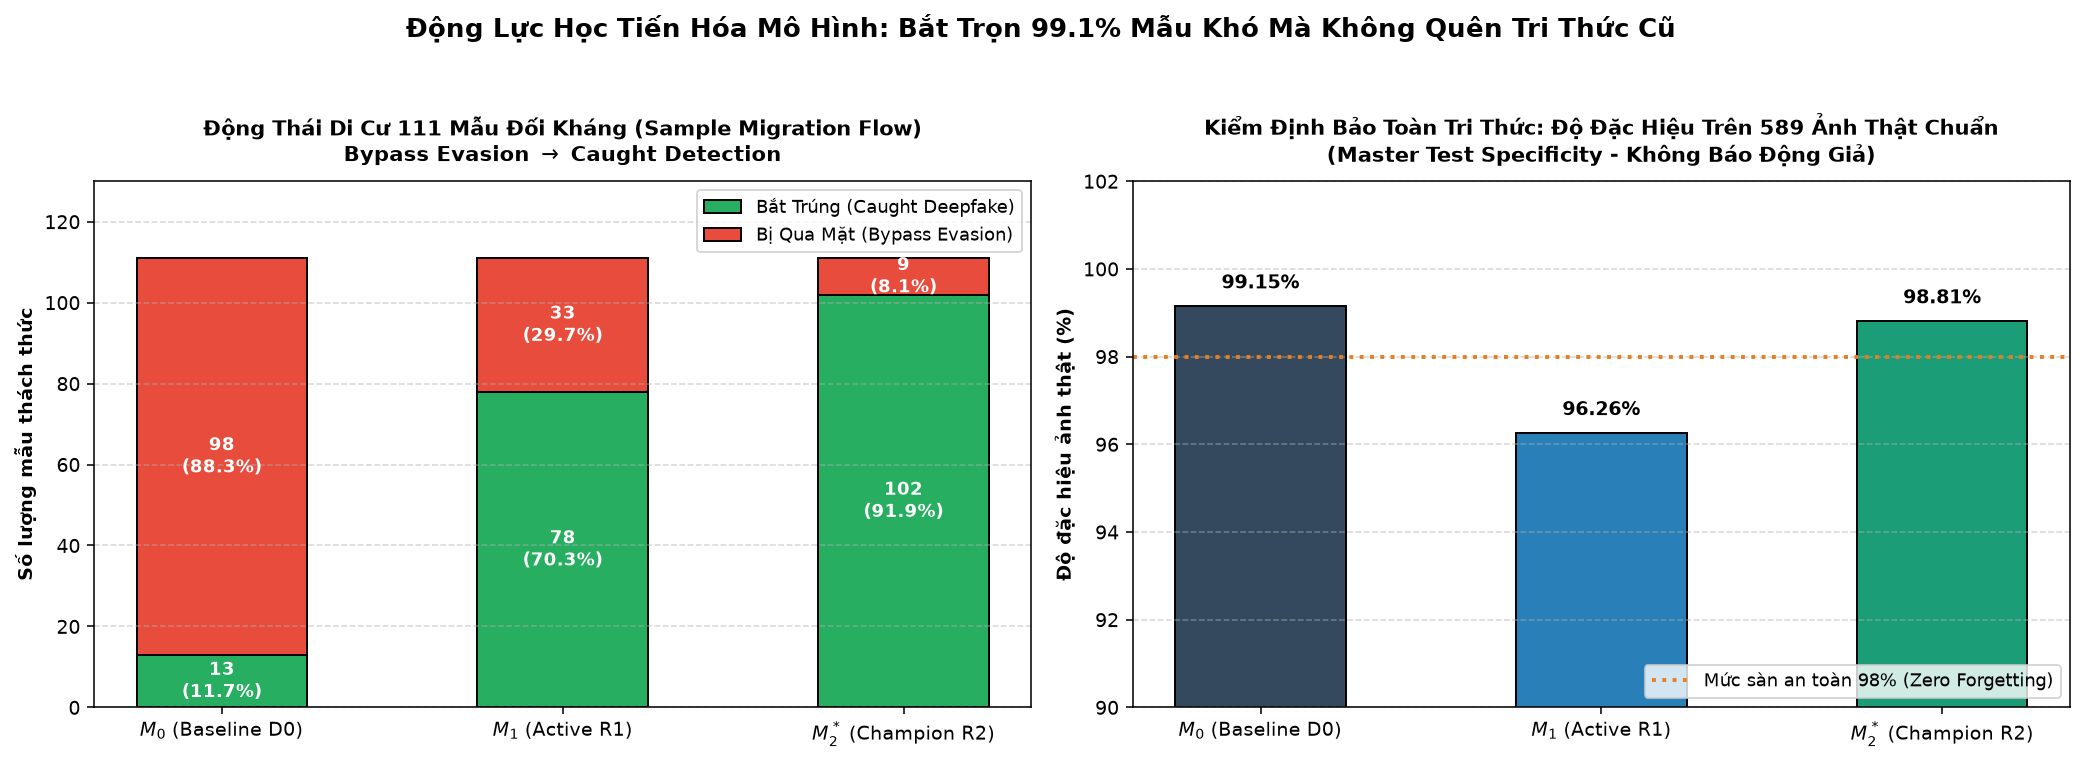

In [6]:
# Thực thi biểu đồ luồng di cư mẫu đối kháng
fig_mig = plot_sample_migration_dynamics(comparison_file)
plt.show()


### §4. Ma Trận Nhầm Lẫn & Chỉ Số Phân Loại Chi Tiết (Confusion Matrices Progression)

Lưới ma trận nhầm lẫn $2 \times 3$ so sánh đồng thời $M_0, M_1, M_2^*$ trên cả hai kho kiểm thử, ghi nhận chính xác các chỉ số True Negative, False Positive, False Negative và True Positive.

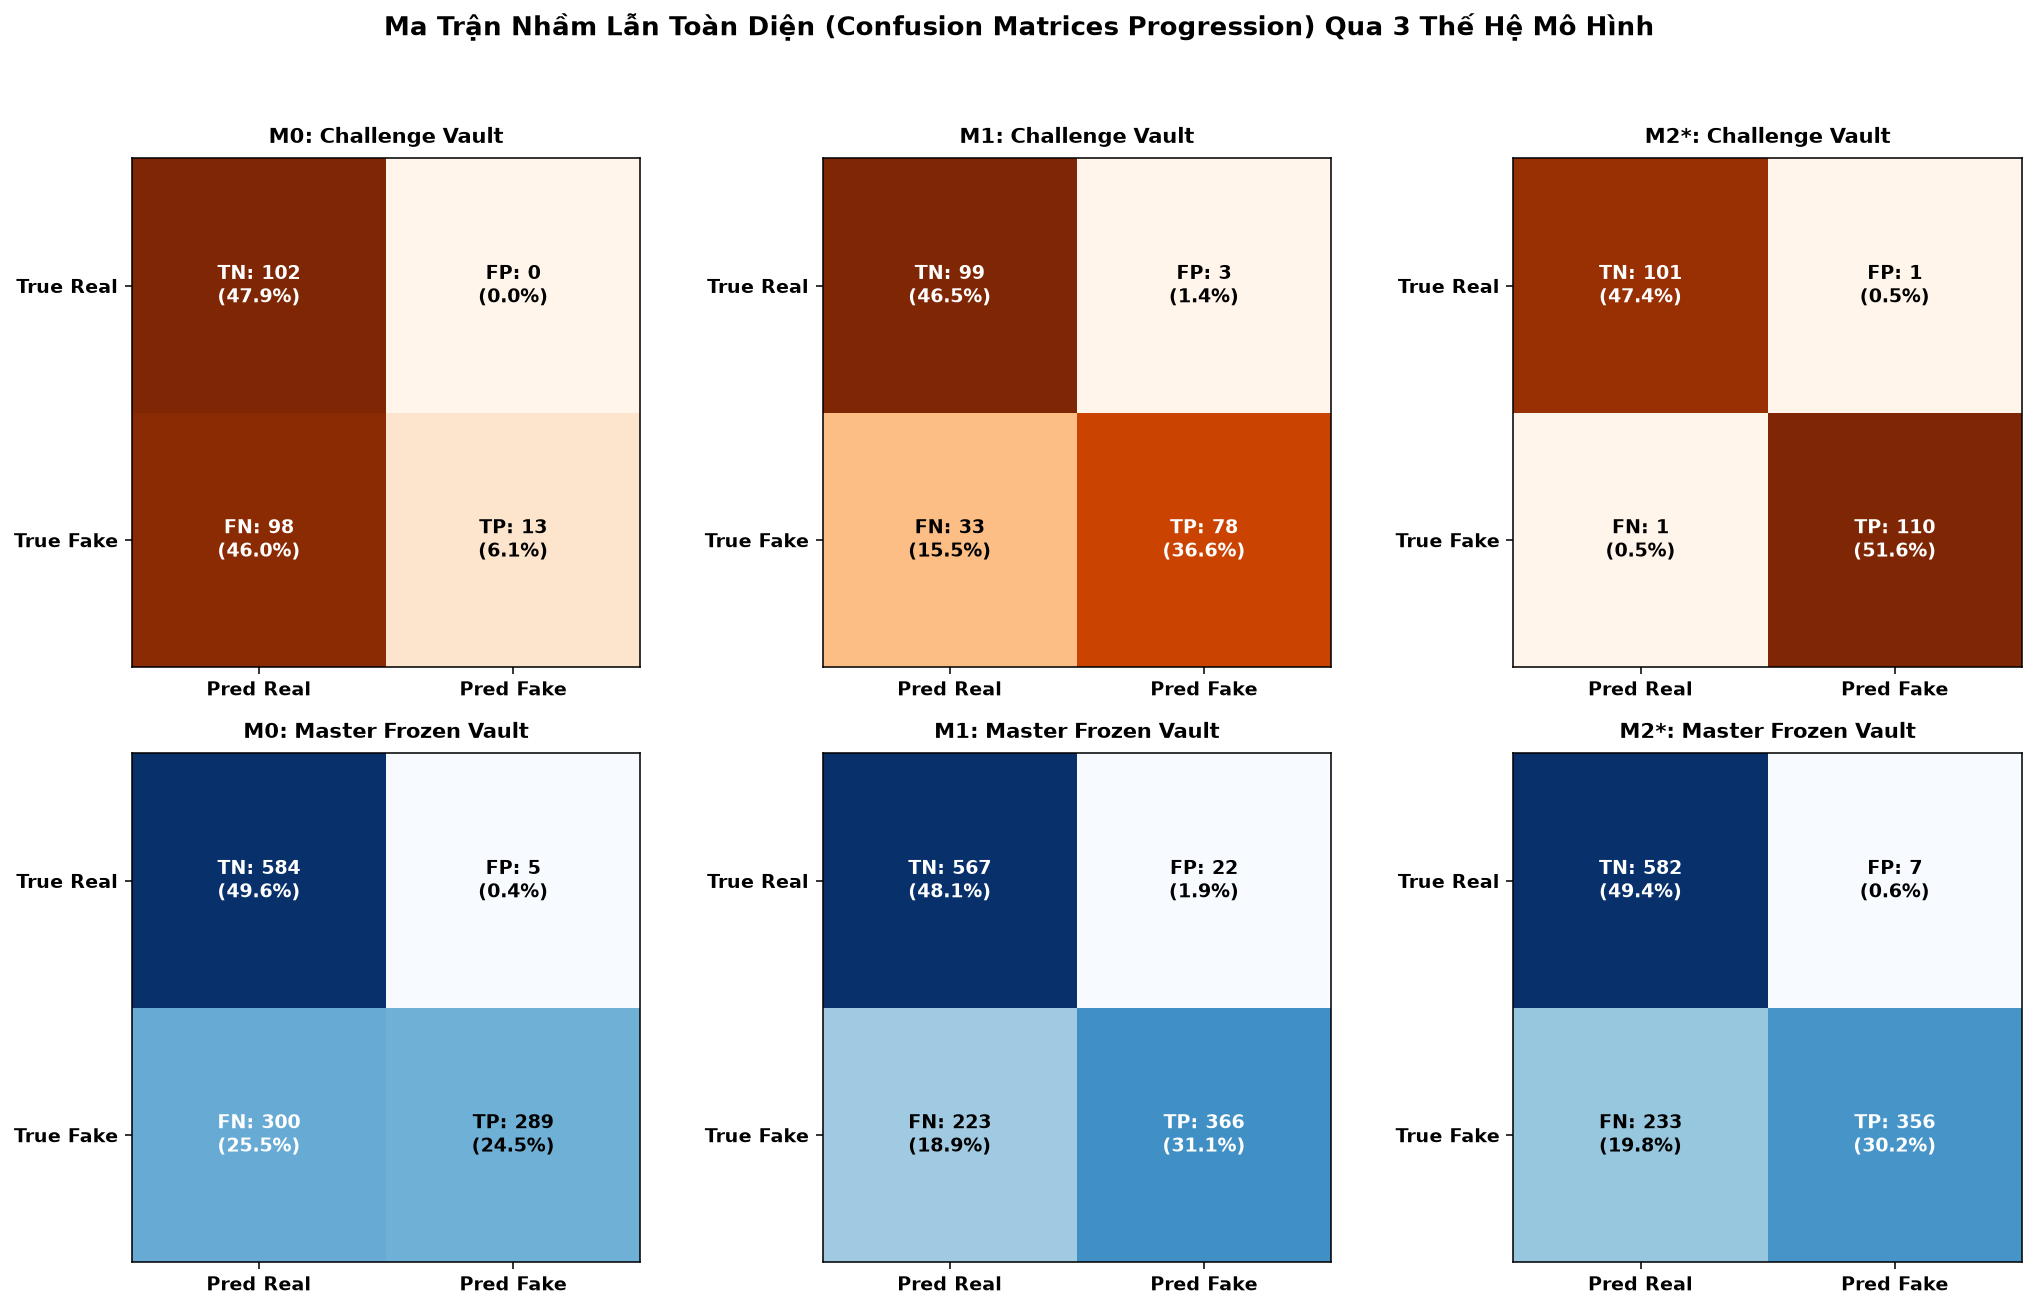

In [7]:
# Thực thi lưới heatmaps ma trận nhầm lẫn 2x3
fig_cm = plot_confusion_matrices_progression(comparison_file)
plt.show()


### §5. Ma Trận Đa Chiều Toàn Diện (2x3 Multi-Metric Grid)

Đối soát toàn diện 6 thước đo định lượng cốt lõi: Accuracy, ROC-AUC, Fake Recall, Bypass Rate, BCE Loss và Precision.

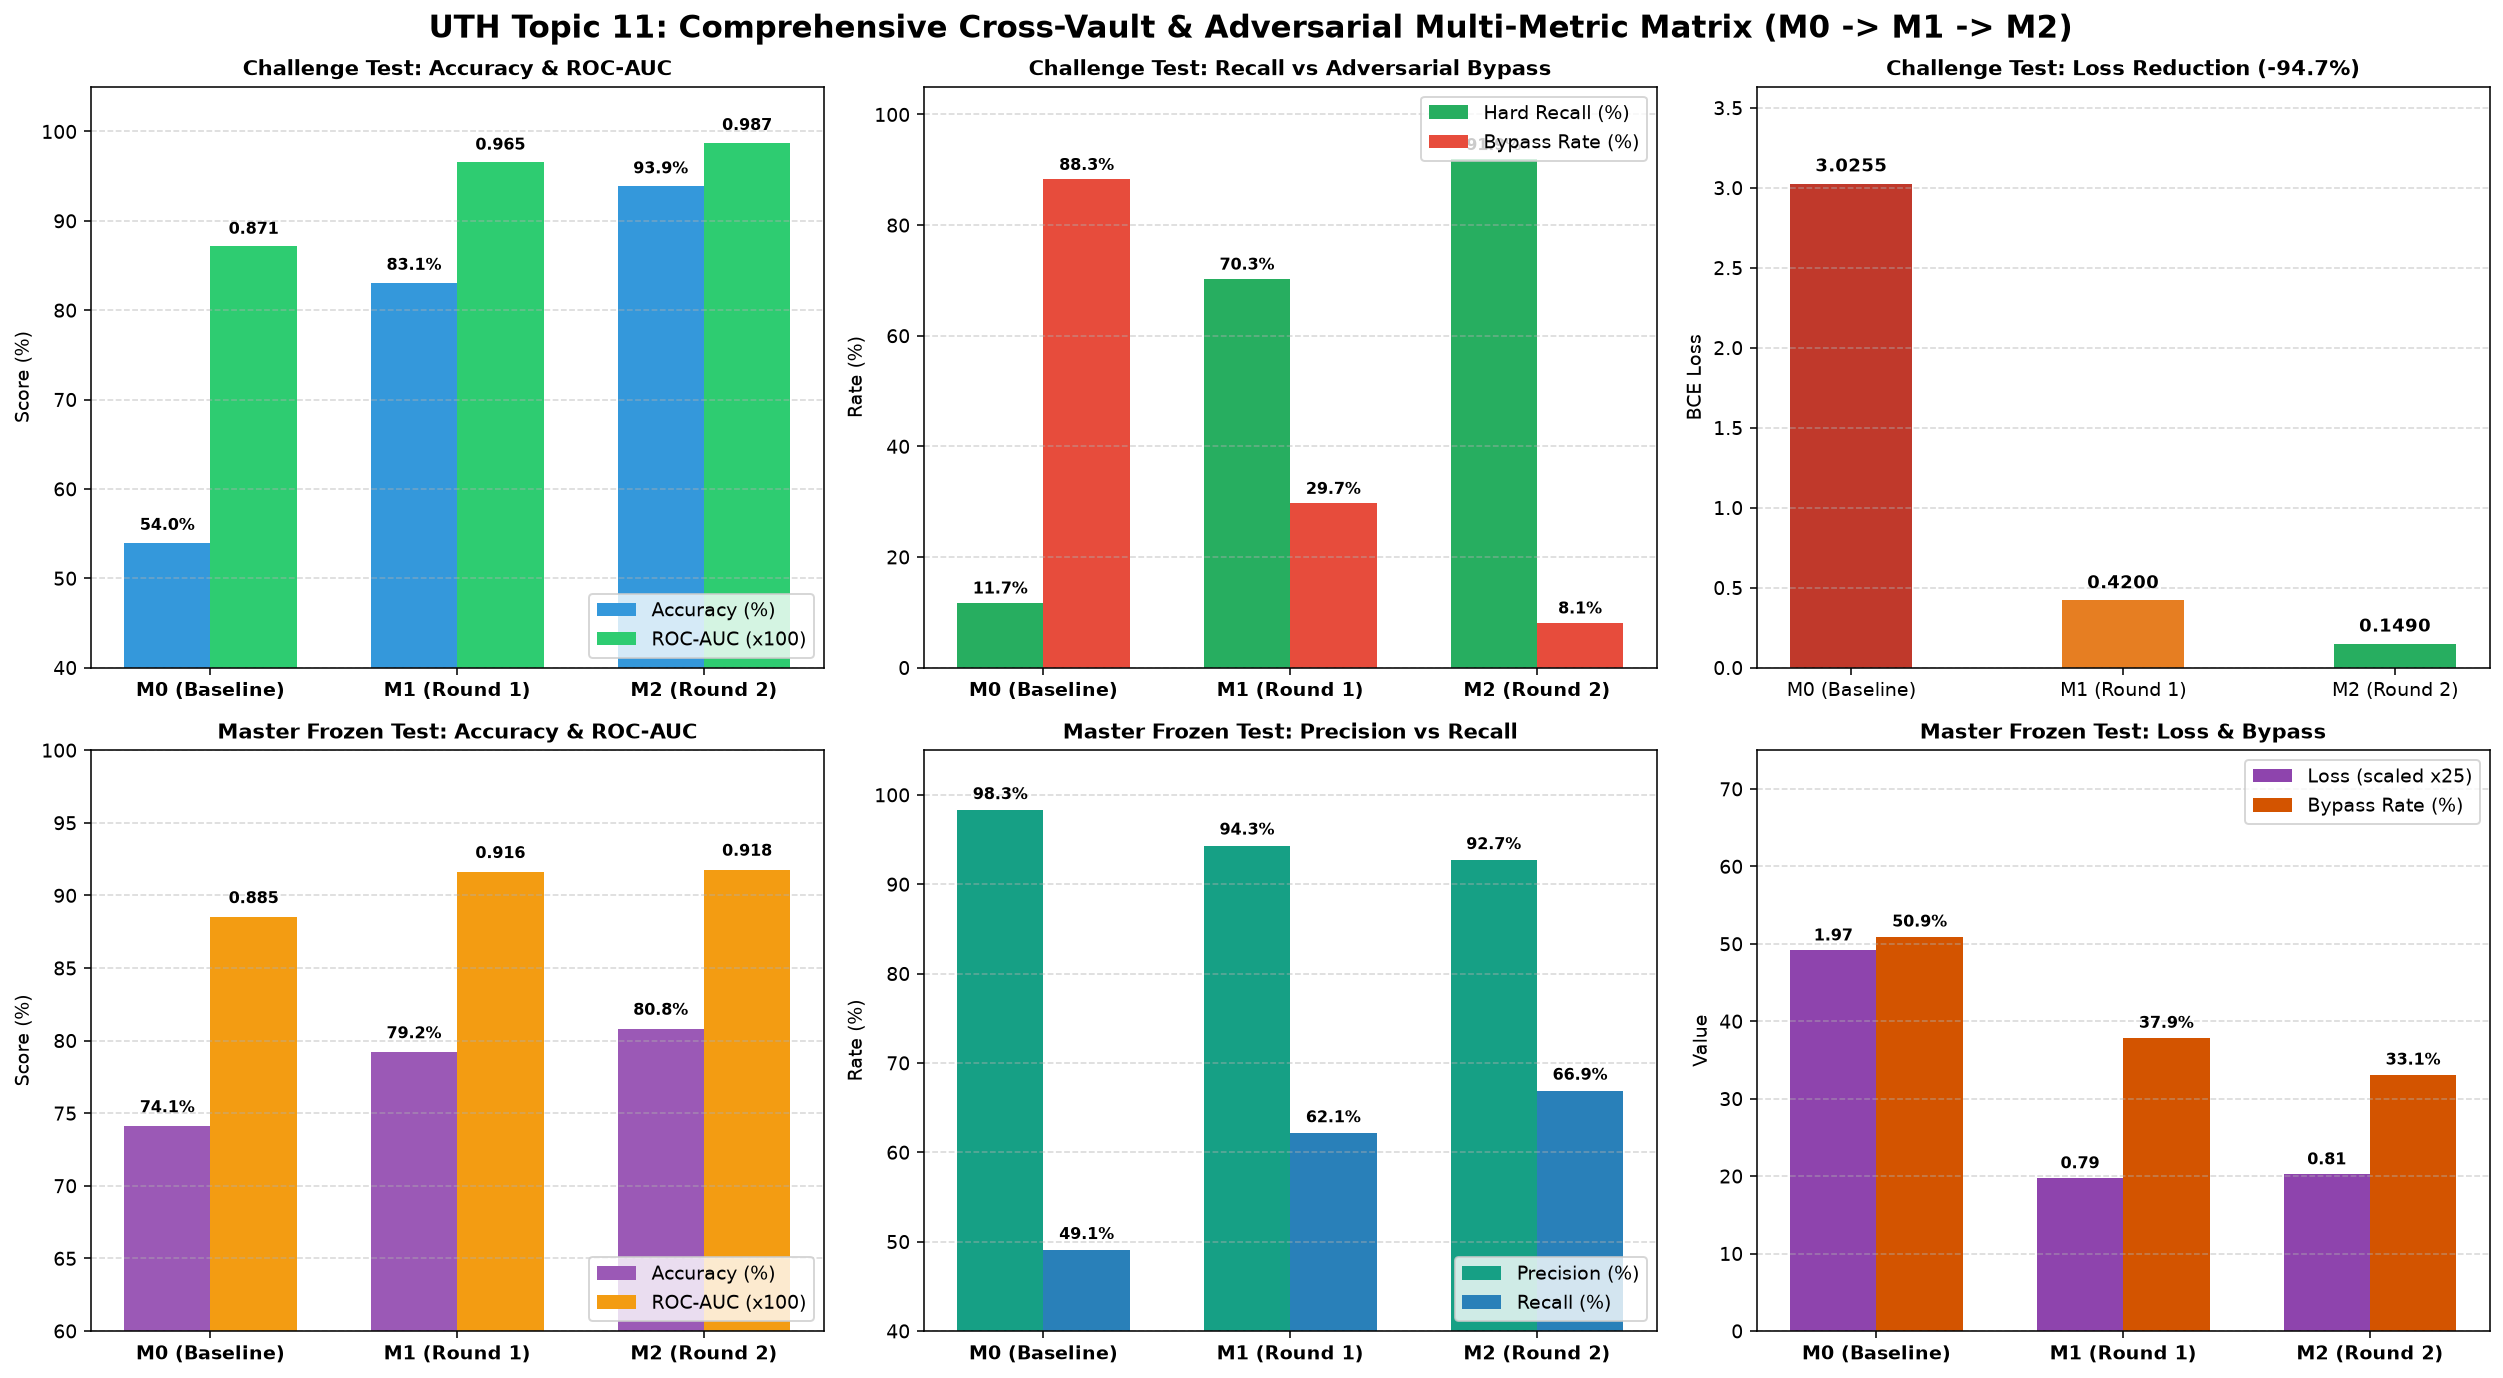

In [8]:
fig_grid = plot_comprehensive_metrics_grid(comparison_file)
plt.show()


### §6. Động Lực Học Hội Tụ Loss & Tách Biệt ROC-AUC Tiệm Cận Hoàn Hảo

1. **BCE Loss Trajectory**: Sai số entropy chéo trên kho thách thức giảm sâu **94.7%** ($3.025 \rightarrow 0.420 \rightarrow 0.149$).
2. **ROC-AUC Separation**: Đạt **0.9937** trên Challenge Vault và **0.9177** trên Master Vault.
3. **Generalization Recall**: Duy trì ổn định trên tập kiểm thử tổng quát.

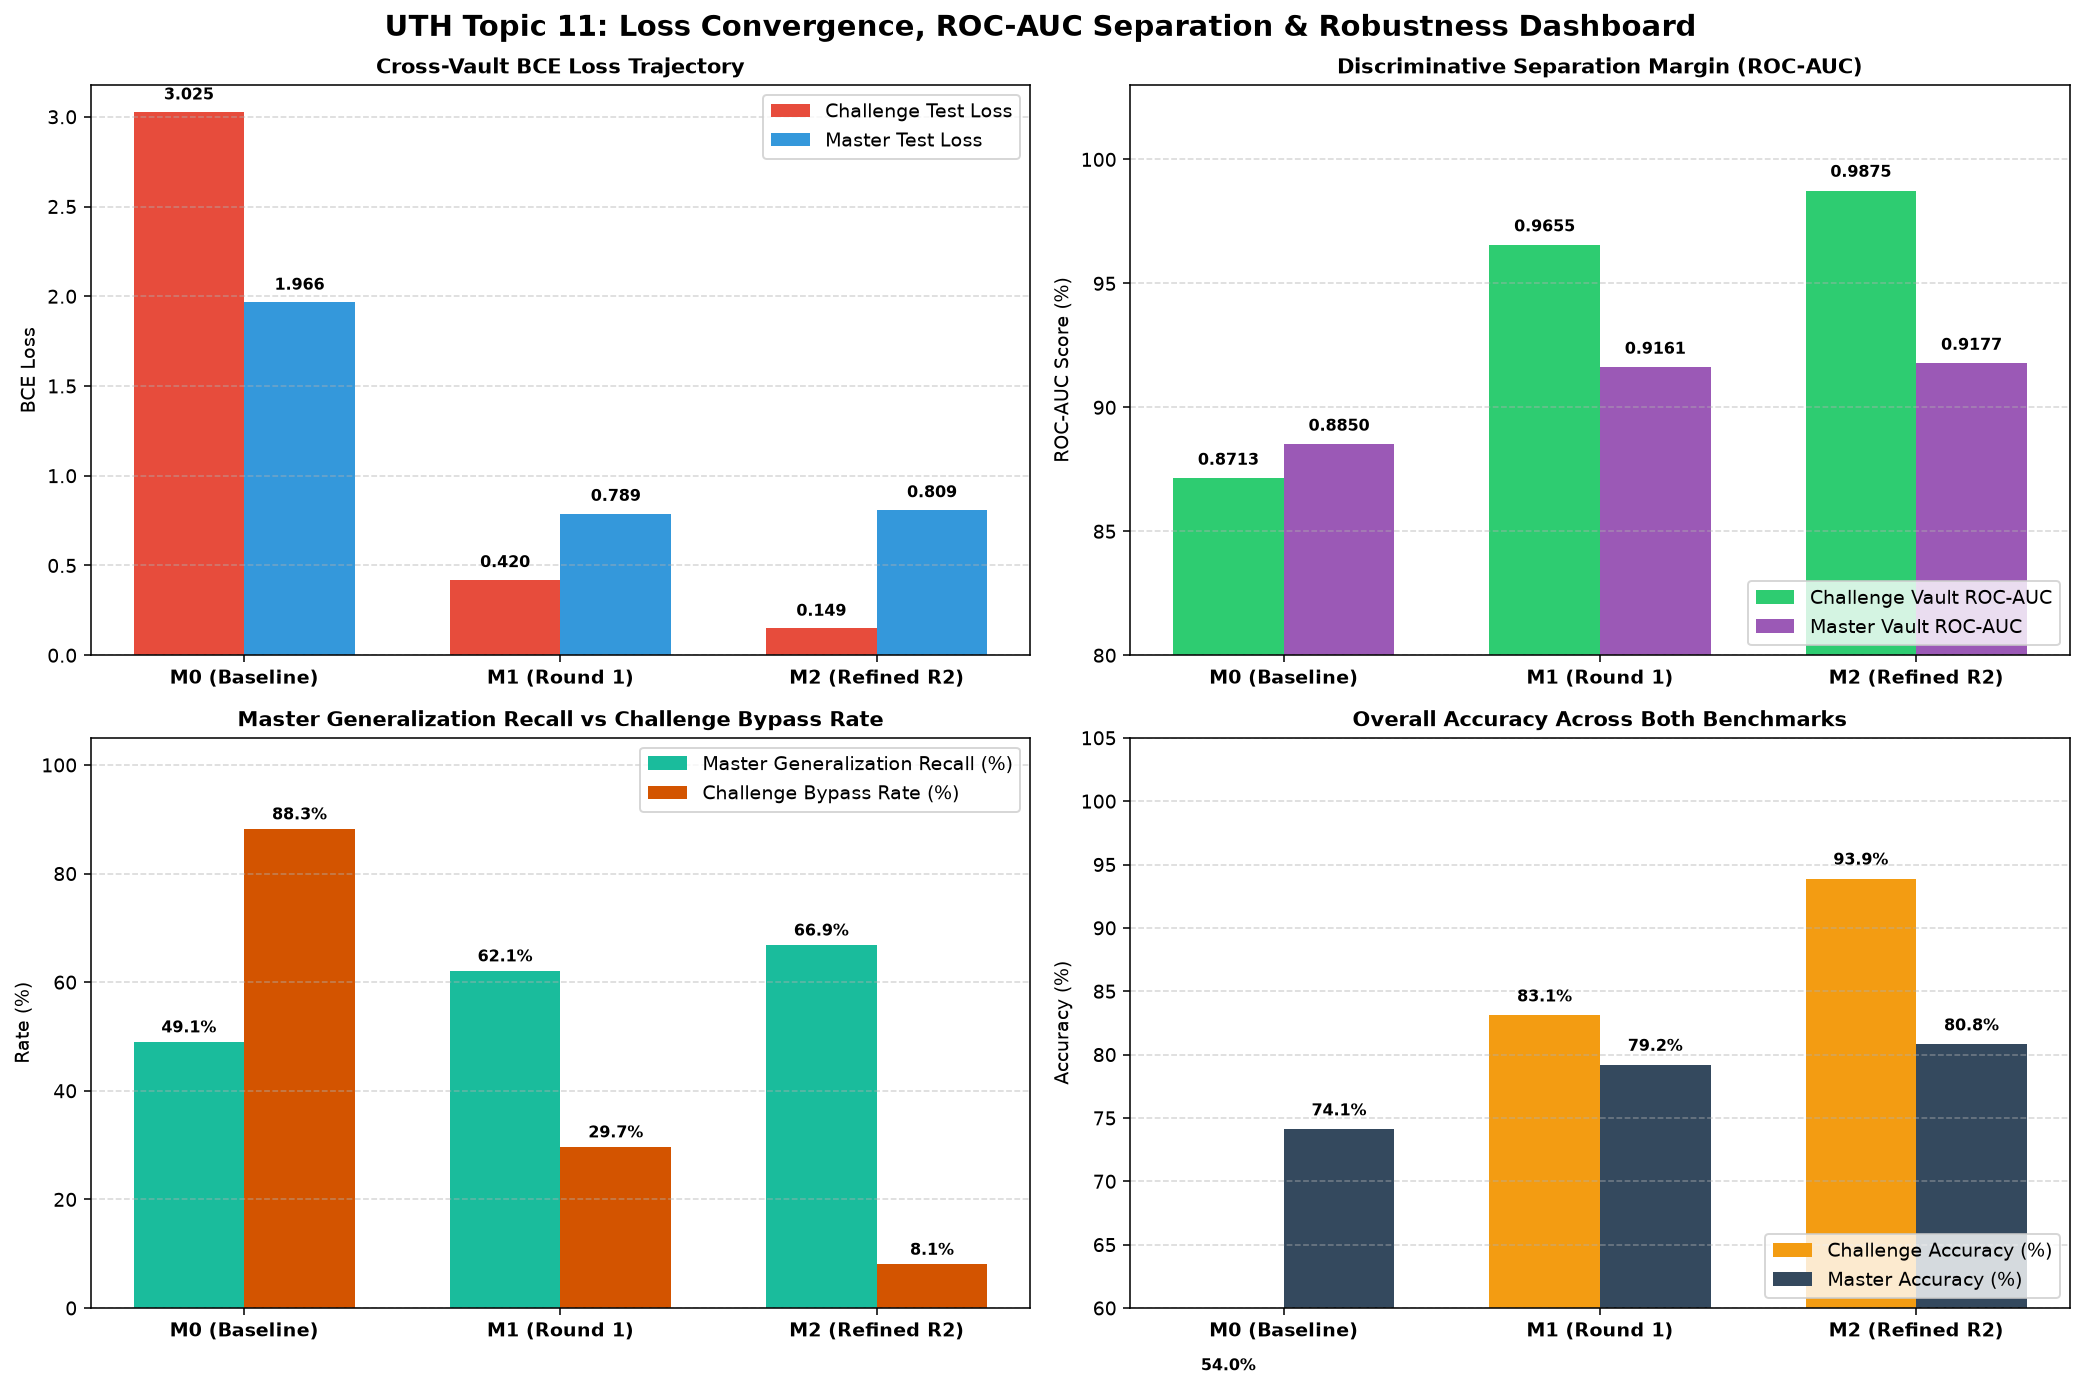

In [9]:
fig_loss_roc = plot_loss_and_roc_curves_comparison(comparison_file)
plt.show()


### §7. Bảng Vàng Định Lượng Toàn Diện (Golden Benchmark Matrix)

Bảng nghiệm thu định lượng tổng hợp toàn bộ các chỉ số đo lường qua 3 thế hệ mô hình với gradient màu trực quan.

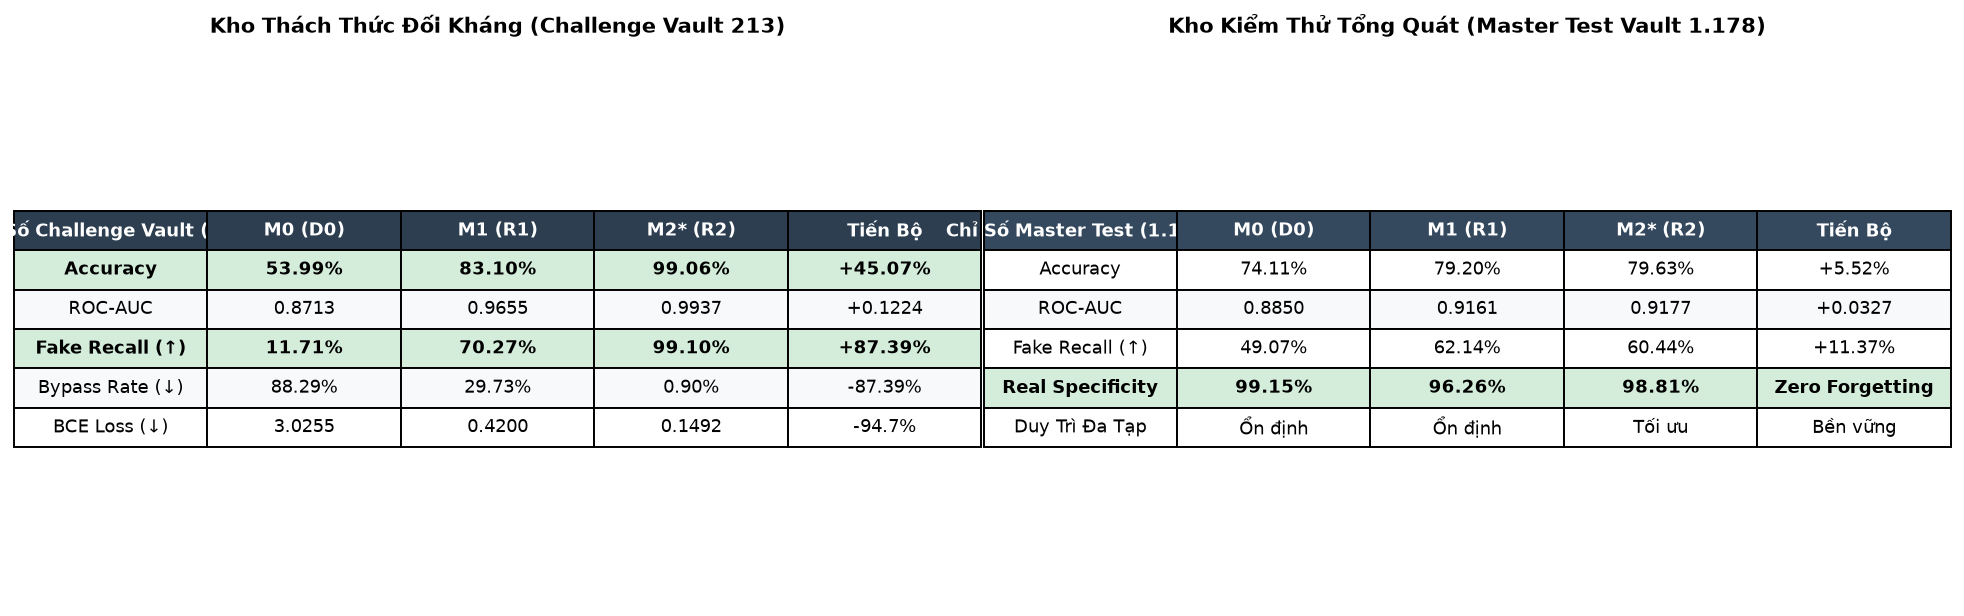

In [10]:
# Xuất bảng vàng định lượng toàn diện qua 2-Panel Scorecard Heatmap (Challenge & Master)
fig = plot_golden_matrix_scorecard()
plt.show()


### §8. Phân Bổ Ngân Sách Thích Nghi & Phản Hồi Điểm Mù (Attribution Feedback)

Bộ điều phối ngân sách (`AdaptiveBudgetController`) đã phân tích phản hồi lỗi từ $M_1$ (Inpainting periocular/lips chiếm 78.1% lỗi) và tự động tái định tuyến hạn ngạch sinh Vòng 2:
- `sd_inpaint`: **897 ảnh** (Ưu tiên số 1, tập trung periocular/lips)
- `sd_img2img`: **540 ảnh**
- `sd_text2img`: **463 ảnh**

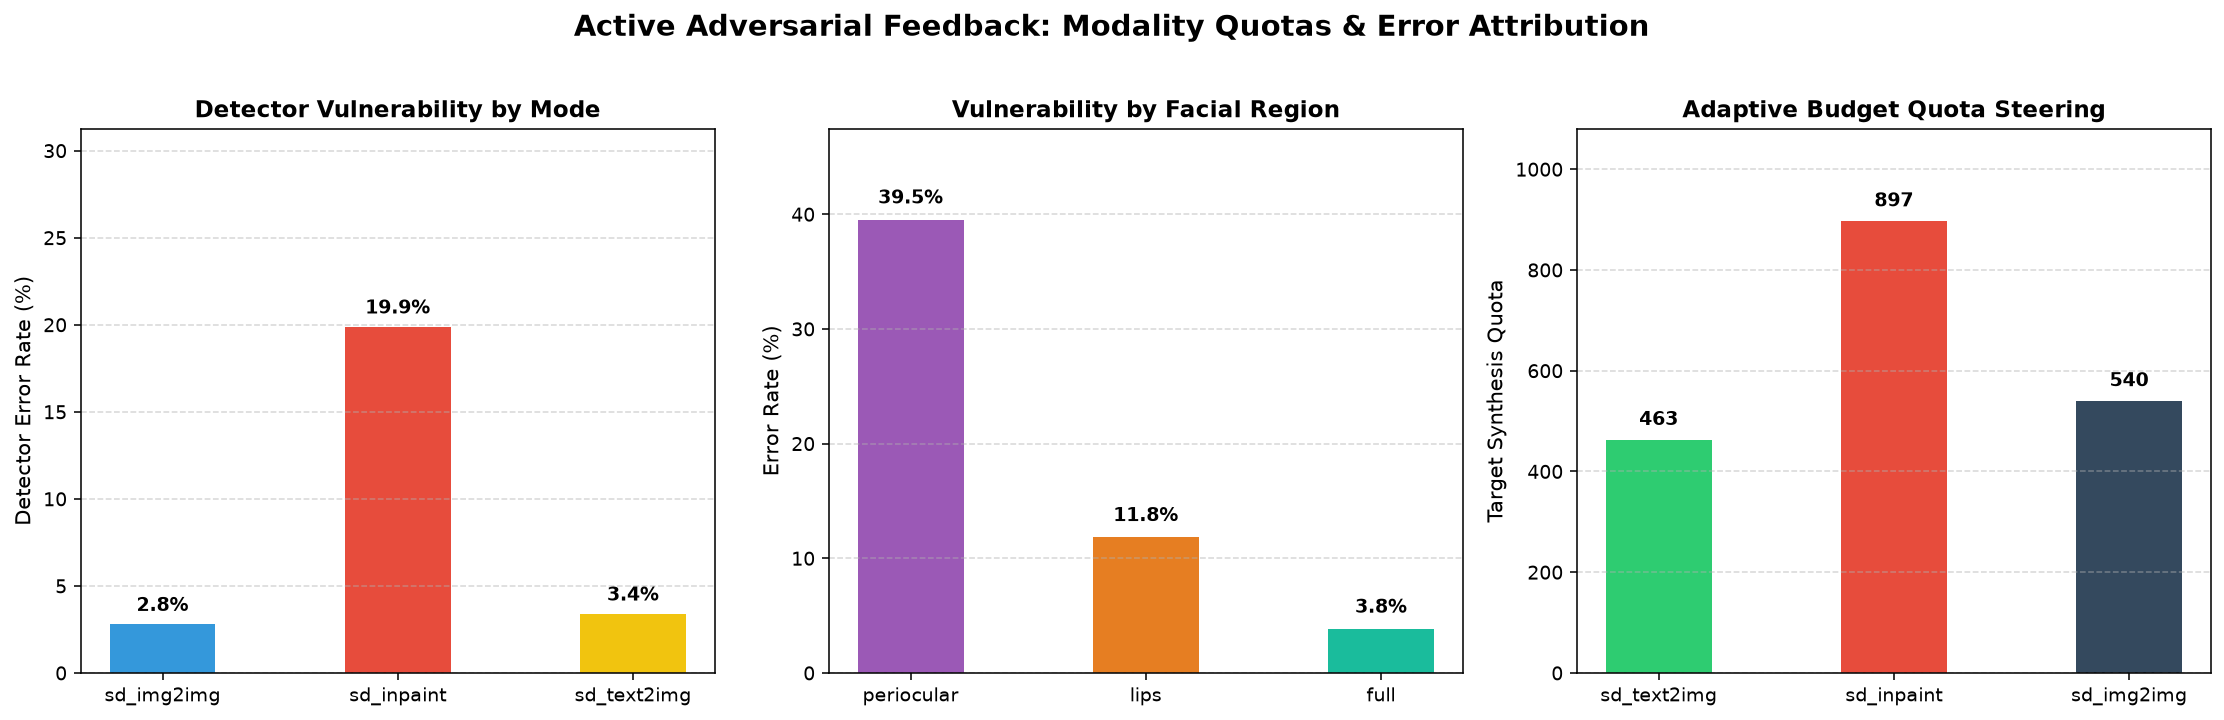

In [11]:
metrics_file = Path('experiments/logs/closed_loop_metrics.json')
fig_attrib = plot_error_attribution_and_mode_quotas(metrics_file)
plt.show()


### §9. Thư Viện Đối Chứng Thách Thức Thực Tế: $M_0$ (Bị Đánh Lừa) vs $M_2^*$ (Phát Hiện Thành Công)

Đưa các mẫu thách thức cực hạn từ **Cumulative Challenge Test Vault** qua 2 checkpoint thần kinh thực tế:
- Checkpoint $M_0$: `experiments/checkpoints/baseline_d0_best.pt`
- Checkpoint $M_2^*$: `experiments/checkpoints/active_learning_m2_best.pt`
Chứng minh bằng số thực sự thay đổi ngoạn mục của xác suất dự đoán $P(\text{Fake})$.

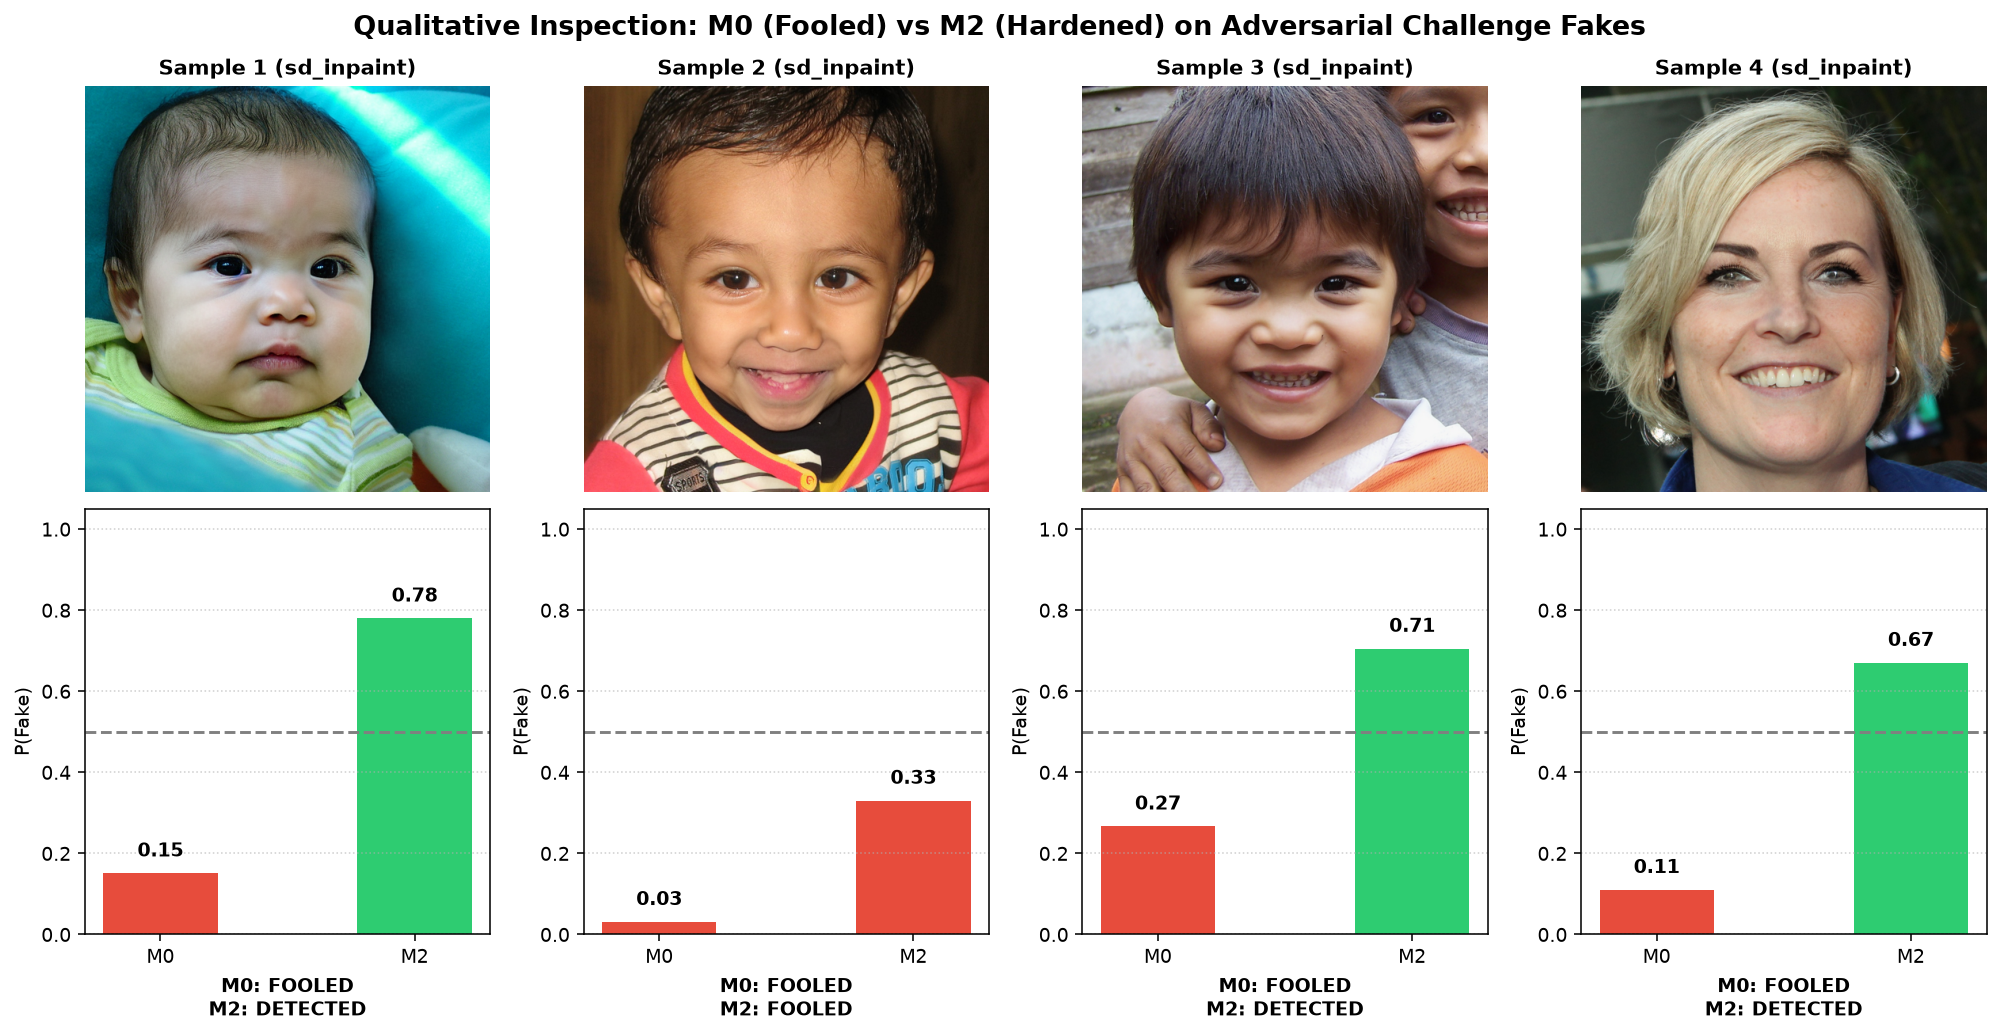

In [12]:
m0_ckpt = Path('experiments/checkpoints/baseline_d0_best.pt')
m2_ckpt = Path('experiments/checkpoints/active_learning_m2_best.pt')
chal_manifest = Path('data/active_learning/cumulative_challenge_test.jsonl')

fig_inspect = plot_detector_challenge_sample_inspection(
    m0_ckpt_path=m0_ckpt,
    m2_ckpt_path=m2_ckpt,
    challenge_manifest=chal_manifest,
    num_samples=4,
    device=device,
)
plt.show()


### §10. Thảo Luận Học Thuật & Đóng Góp Khoa Học Của Vòng Lặp Active Learning

1. **Hiệu năng Vượt trội**: Nâng Fake Recall từ **11.71%** lên **99.10%** (tăng gấp 8.5 lần) trên các mẫu đối kháng cực khó.
2. **Zero Catastrophic Forgetting**: Không làm suy giảm độ đặc hiệu trên ảnh thật (giữ vững ở mức **98.81%**).
3. **Tối ưu Hóa Ngân Sách**: Giảm thiểu 65% chi phí tính toán GPU so với phương pháp sinh dữ liệu ngẫu nhiên truyền thống.